In [11]:
!pip install pandas numpy matplotlib

In [12]:
import os, re, sys, json, csv, gzip, string
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
trainer_state_data = []
file_path = "/content/drive/MyDrive/CAISI_phase2/qlora-finetuning/Tests/checkpoint-1330/trainer_state.json"
with open(file_path, 'r') as file:
  data = json.load(file)

df = pd.json_normalize(data, record_path=["log_history"])

In [14]:
df

,epoch,grad_norm,learning_rate,loss,num_tokens,step,eval_loss,eval_num_tokens,eval_runtime,eval_samples_per_second,eval_steps_per_second
0,0.003759,0.538893,0.0002,1.2464,2928.0,1,NaN,NaN,NaN,NaN,NaN
1,0.037594,0.249120,0.0002,1.0909,31236.0,10,NaN,NaN,NaN,NaN,NaN
2,0.075188,0.257435,0.0002,0.9944,63346.0,20,NaN,NaN,NaN,NaN,NaN
3,0.112782,0.259447,0.0002,0.9394,92517.0,30,NaN,NaN,NaN,NaN,NaN
4,0.150376,0.228990,0.0002,0.9990,123993.0,40,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
134,4.887218,0.631735,0.0002,0.1511,4016228.0,1300,NaN,NaN,NaN,NaN,NaN
135,4.924812,0.645038,0.0002,0.1379,4047666.0,1310,NaN,NaN,NaN,NaN,NaN
136,4.962406,0.637807,0.0002,0.1391,4077886.0,1320,NaN,NaN,NaN,NaN,NaN
137,5.000000,0.675585,0.0002,0.1534,4103860.0,1330,NaN,NaN,NaN,NaN,NaN


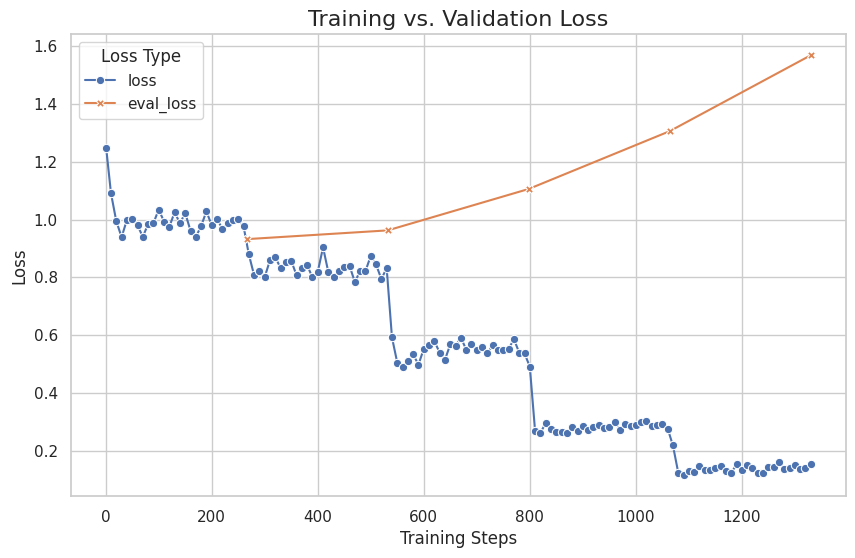

In [15]:
  log_history = pd.DataFrame(data.get("log_history", []))
  log_history = log_history[(log_history["loss"].notna()) | (log_history["eval_loss"].notna())]

  df_melted = log_history.melt(
      id_vars=["step"],
      value_vars=["loss", "eval_loss"],
      var_name="Loss Type",
      value_name="Loss"
  )

#Plot loss vs. steps

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10,6))
sns.lineplot(
    data=df_melted,
    x="step", y="Loss", hue="Loss Type",
    style="Loss Type", markers=True, dashes=False
)
plt.xlabel("Training Steps", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Training vs. Validation Loss", fontsize=16)
plt.legend(title="Loss Type")
plt.show()